# Satellite features extraction

Following up on notebook `02_ground_truth_extraction.ipynb`, this section pulls satellite data from Earth Engine's repositories. This data will later down the pipeline be used to train a machine learning model to predict pollution in the monitoring deserts.


In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import dotenv
import pickle
import gzip
import shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import yaml
import glob

import ee
import geemap

import monitoring_deserts.data.fetch_earthengine as fetch_ee

## Configuration

Read the configuration parameters from the previous steps and the general project config. Initialize the Earth Engine
client.

In [3]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)
    
RAW_DATA_DIR = Path(gen_config["data_dir"]["raw"]) / "satellite"
CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"]) / "satellite"
PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
MAPS_DIR = Path(gen_config["output_dir"]["maps"]) / "satellite"
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "satellite"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
MAPS_DIR.mkdir(parents=True, exist_ok=True)

# Spacetime settings
with open("../configs/census_scope.yaml") as f:
    census_config = yaml.safe_load(f)

BOUNDING_BOX = tuple(census_config["bounding_box"].values())
DAY_START, DAY_END = census_config["period"]["start"], census_config["period"]["end"]

# Earth Engine parameters
BUFFER_RADIUS = 2000
REDUCER_SCALE = 1000

# Open the ground truth df obtained in notebook 2
gtruth_df = pd.read_parquet(CLEAN_DATA_DIR / "../ground_truth/ground_truth_clean.parquet")

# Initialize client
dotenv.load_dotenv()
ee.Initialize(project="monitoring-deserts")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Step 1 - Configuring the request

Build the computation graph for requesting Earth Engine data for tropospheric NO2 and absorbing aerosol index (AAI).

In [4]:
# NO2 image collection
no2_image_collection = (ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
         .select("tropospheric_NO2_column_number_density"))
# Aerosol index image collectin
aai_image_collection = (ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_AER_AI")
         .select("absorbing_aerosol_index"))

# Build a feature collection to hold the regions for later reduction
unique_stations = gtruth_df[["station_id", "longitude", "latitude"]].drop_duplicates("station_id")
station_fc = fetch_ee.stations_to_feature_collection(unique_stations, radius_m=BUFFER_RADIUS)

# Build the monthly window where the data gets averaged
m_win = fetch_ee.build_month_windows(DAY_START, DAY_END)

TMP_DATA_DIR = RAW_DATA_DIR / "tmp"
TMP_DATA_DIR.mkdir(parents=True, exist_ok=True)
def _cache_pulled_data(month, df, im_name):
    df.to_parquet(TMP_DATA_DIR / f"tmp_{month}_{im_name}.parquet")

## Step 2 - Pull the data
Very time-consuming step to run locally, so after the first succesful pull just load the .parquet files.

In [5]:
# Pull and save the monthly statistics for NO2 and AAI
no2_stats = fetch_ee.pull_monthly_stats(no2_image_collection,
                                        station_fc,
                                        m_win,
                                        "no2",
                                        scale=REDUCER_SCALE,
                                        on_month_done=_cache_pulled_data,
                                       )
no2_df = pd.concat(no2_stats, ignore_index=True)
no2_df.to_parquet(RAW_DATA_DIR / "no2_df.parquet")
aai_stats = fetch_ee.pull_monthly_stats(aai_image_collection,
                                        station_fc,
                                        m_win,
                                        "aai",
                                        scale=REDUCER_SCALE,
                                        on_month_done=_cache_pulled_data,
                                       )
aai_df = pd.concat(aai_stats, ignore_index=True)
aai_df.to_parquet(RAW_DATA_DIR / "aai_df.parquet")

# If the stats pulls work as intended, wipe the temporary data directories
shutil.rmtree(TMP_DATA_DIR, ignore_errors=True)

In [8]:
# Load the dataframes from disk
aai_df = pd.read_parquet(RAW_DATA_DIR / "aai_df.parquet")
no2_df = pd.read_parquet(RAW_DATA_DIR / "no2_df.parquet")

## Step 3 - Data checks and exploration

In [9]:
# Check for missing values
print(f"Missing in NO2: \n{no2_df['mean'].isna().value_counts()}")
print(f"Missing in AAI: \n{aai_df['mean'].isna().value_counts()}")

Missing in NO2: 
mean
False    5492
True       12
Name: count, dtype: int64
Missing in AAI: 
mean
False    5504
Name: count, dtype: int64


In [10]:
# Find patterns in the missing data
missing_by_month = (no2_df["mean"]
                    .isna()
                    .groupby(no2_df["month"])
                    .agg(["sum", "mean"])
                    .rename(columns={"sum" : "n_missing", "mean" : "n_missing / tot"})
                    .sort_values("n_missing", ascending=False)
                   )
missing_by_month

,n_missing,n_missing / tot
month,,
2025-07-01,6,0.017442
2025-09-01,5,0.014535
2025-08-01,1,0.002907
2025-03-01,0,0.000000
2025-06-01,0,0.000000
2025-05-01,0,0.000000
2025-04-01,0,0.000000
2025-10-01,0,0.000000
2025-11-01,0,0.000000


In [11]:
missing_by_station = (no2_df["mean"]
                      .isna()
                      .groupby(no2_df["station_id"])
                      .agg(["sum", "mean"])
                      .rename(columns={"sum" : "n_missing", "mean" : "n_missing / tot"})
                      .sort_values("n_missing", ascending=False)
                     )
missing_by_station[missing_by_station["n_missing"] > 0]

,n_missing,n_missing / tot
station_id,,
3409455,2,0.1250
3409438,1,0.0625
3409451,1,0.0625
3409453,1,0.0625
7752,1,0.0625
3409523,1,0.0625
3409475,1,0.0625
3409471,1,0.0625
3410005,1,0.0625


In [12]:
# Check whether things are consistent between the previous notebook and this one
print("Number of stations in:")
print(f" Ground truth DataFrame: {gtruth_df['station_id'].nunique()}")
print(f" NO2 DataFrame: {no2_df['station_id'].nunique()}")
print(f" AAI DataFrame: {aai_df['station_id'].nunique()}")
print("Number of analysis months in:")
print(f" Ground truth DataFrame: {gtruth_df['month'].nunique()}")
print(f" NO2 DataFrame: {no2_df['month'].nunique()}")
print(f" AAI DataFrame: {aai_df['month'].nunique()}")

Number of stations in:
 Ground truth DataFrame: 344
 NO2 DataFrame: 344
 AAI DataFrame: 344
Number of analysis months in:
 Ground truth DataFrame: 17
 NO2 DataFrame: 16
 AAI DataFrame: 16


There is one extra month in the ground truth df. This is due to an erroneous interpretation of the half open interval, so that
in this case the last month is `2026-07` and the data for it in gtruth_df has been fully loaded. _I will fix it at the end of the 
project, for now I just drop those rows from the df._

In [13]:
if "2026-07" in gtruth_df["month"].unique():
    gtruth_df = gtruth_df[gtruth_df["month"] != "2026-07"]
    gtruth_df.to_parquet(CLEAN_DATA_DIR / "ground_truth_mod.parquet")
print("Number of analysis months in:")
print(f" Ground truth DataFrame: {gtruth_df['month'].nunique()}")
print(f" NO2 DataFrame: {no2_df['month'].nunique()}")
print(f" AAI DataFrame: {aai_df['month'].nunique()}")

Number of analysis months in:
 Ground truth DataFrame: 16
 NO2 DataFrame: 16
 AAI DataFrame: 16


<Axes: >

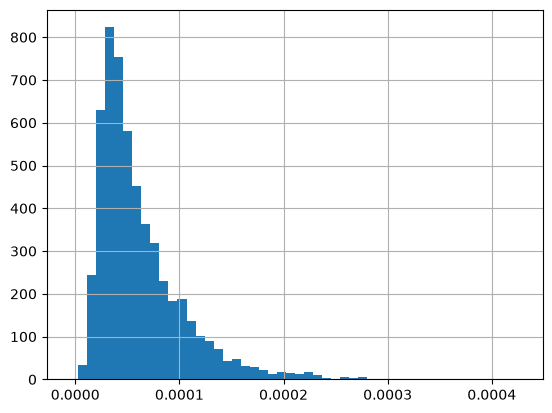

In [14]:
# Quick checks on the distributions
no2_df["mean"].hist(bins=50)

<Axes: >

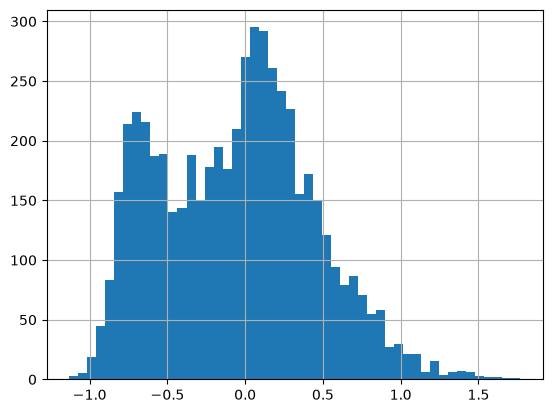

In [15]:
aai_df["mean"].hist(bins=50)

## Step 4 - Merge the dataframes into a single satellite dataframe

In [16]:
aai_df = aai_df.rename(columns={"station_id" : "station_id",
                                "month" : "month",
                                "mean" : "aai",
                                "stdDev" : "aai_sd"
                               }
                      )[["station_id", "month", "aai", "aai_sd"]]
aai_df["aai_units"] = "dimensionless"
no2_df = no2_df.rename(columns={"station_id" : "station_id",
                                "month" : "month",
                                "mean" : "no2",
                                "stdDev" : "no2_sd"
                               }
                      )[["station_id", "month", "no2", "no2_sd"]]
no2_df["no2_units"] = "mol/m2"
satellite_df = no2_df.merge(aai_df, on=["station_id", "month"])
satellite_df["month"] = satellite_df["month"].dt.to_period("M") # For compatibility with gtruth_df
satellite_df.head()

,station_id,month,no2,no2_sd,no2_units,aai,aai_sd,aai_units
0,50,2025-03,0.000106,0.000004,mol/m2,0.208134,0.009537,dimensionless
1,235,2025-03,0.000134,0.000005,mol/m2,0.236869,0.021313,dimensionless
2,860,2025-03,0.000058,0.000001,mol/m2,0.331405,0.024480,dimensionless
3,2456,2025-03,0.000051,0.000001,mol/m2,0.428689,0.022733,dimensionless
4,5408,2025-03,0.000067,0.000004,mol/m2,-0.063205,0.019414,dimensionless


In [17]:
satellite_df.to_parquet(CLEAN_DATA_DIR / "satellite_df.parquet")

## Step 5 - Merge satellite and ground dataframes

Start building towards the clean, full dataframe including all the relevant data.

In [18]:
analysis_df = satellite_df.merge(gtruth_df, on=["station_id", "month"])
analysis_df = analysis_df.rename(columns={"unit" : "pm25_units", "nan_reason" : "pm25_nan_reason"})
analysis_df = analysis_df.set_index(["month", "station_id", "longitude", "latitude"]) # Quick column reordering
analysis_df = analysis_df.reset_index()
analysis_df.head()

,month,station_id,longitude,latitude,no2,no2_sd,no2_units,aai,aai_sd,aai_units,pm25,pm25_sd,pm25_units,pm25_nan_reason
0,2025-03,50,77.131023,28.674045,0.000106,0.000004,mol/m2,0.208134,0.009537,dimensionless,78.702397,25.853544,ugm3,none
1,2025-03,235,77.316032,28.646835,0.000134,0.000005,mol/m2,0.236869,0.021313,dimensionless,81.005496,31.516710,ugm3,none
2,2025-03,860,78.005981,27.198658,0.000058,0.000001,mol/m2,0.331405,0.024480,dimensionless,57.440896,17.897299,ugm3,none
3,2025-03,2456,80.891736,26.833997,0.000051,0.000001,mol/m2,0.428689,0.022733,dimensionless,58.161202,20.561508,ugm3,none
4,2025-03,5408,80.518167,16.515083,0.000067,0.000004,mol/m2,-0.063205,0.019414,dimensionless,24.145945,15.724409,ugm3,none


## Step 6 - Save cleaned data and notebook metadata

In [ ]:
# Partial analysis dataframe
analysis_df.to_parquet(CLEAN_DATA_DIR / "analysis_df.parquet")

# Notebook metadata
metadata = {
    "station_buffer_radius" : BUFFER_RADIUS,
    "reducer_scale_m" : REDUCER_SCALE,
    "image_collections" : {
        "no2" : "COPERNICUS/S5P/OFFL/L3_NO2:tropospheric_NO2_column_number_density",
        "aai" : "COPERNICUS/S5P/OFFL/L3_AER_AI:absorbing_aerosol_index"
    },
    "units" : {
        "no2" : "mol/m2",
        "aai" : "dimensionless"
    },
    "n_stations" : int(analysis_df['station_id'].nunique()),
    "n_months" : int(analysis_df['month'].nunique()),
    "n_data_points" : len(analysis_df),
    "missing_no2" : len(analysis_df) - int(analysis_df["no2"].isna().value_counts()[False]),
    "missing_aai" : len(analysis_df) - int(analysis_df["aai"].isna().value_counts()[False]),
    "missing_no2_info" : {
        "worst_station_id" : str(missing_by_station.iloc[0].name),
        "worst_station_count" : int(missing_by_station.iloc[0].n_missing),
        "worst_station_pct" : f"{round(float(missing_by_station.iloc[0].n_missing / analysis_df.month.nunique()) * 100, 1)}%",
        "worst_month" : missing_by_month.iloc[0].name.strftime("%Y-%m-%d"),
        "worst_month_count" : int(missing_by_month.iloc[0].n_missing),
        "worst_month_pct" : f"{round(float(missing_by_month.iloc[0].n_missing / analysis_df.station_id.nunique()) * 100, 1)}%",
    },
}
    
with open("../configs/satellite_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False) 
